# E-commerce Data Analyst — Python Workflow
Notebook minh họa quy trình: đọc dữ liệu → kiểm tra chất lượng → làm sạch → tạo Star Schema → KPI và biểu đồ.
Đặt file CSV nguồn cùng thư mục với notebook hoặc sửa `INPUT_FILE` bên dưới.

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

INPUT_FILE = "ecommerce_orders_dataset (1).csv"
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)
raw = pd.read_csv(INPUT_FILE)
print("Shape:", raw.shape)
display(raw.head())
display(raw.dtypes.to_frame("dtype"))


Shape: (30000, 41)


,Order_ID,Customer_ID,Order_Date,Year,Month,Day,Day_Of_Week,Quarter,Customer_Age,Customer_Gender,...,Delivery_Days,Order_Status,Returned,Review_Rating,Customer_Lifetime_Value,Profit_Margin_Percent,Profit_Amount,Season,Holiday_Season,High_Value_Order
0,615717,CUST007322,2023-01-01,2023,1,1,Sunday,1,32,Male,...,2,Delivered,No,4.4,2144.92,23.10,15.75,Winter,No,No
1,626919,CUST004717,2023-01-01,2023,1,1,Sunday,1,50,Male,...,9,Delivered,No,4.1,817.17,8.57,3.32,Winter,No,No
2,615781,CUST004415,2023-01-01,2023,1,1,Sunday,1,61,Male,...,2,Delivered,No,5.0,541.16,29.72,45.67,Winter,No,No
3,621747,CUST004114,2023-01-01,2023,1,1,Sunday,1,34,Male,...,6,Returned,Yes,3.4,700.49,25.22,75.25,Winter,No,No
4,625881,CUST000145,2023-01-01,2023,1,1,Sunday,1,37,Male,...,8,Delivered,No,3.6,2133.77,24.64,26.06,Winter,No,No


,dtype
Order_ID,int64
Customer_ID,object
Order_Date,object
Year,int64
Month,int64
Day,int64
Day_Of_Week,object
Quarter,int64
Customer_Age,int64
Customer_Gender,object


## 1. Kiểm tra chất lượng dữ liệu

In [8]:
quality = pd.DataFrame({
    "missing": raw.isna().sum(),
    "unique": raw.nunique(dropna=True),
    "dtype": raw.dtypes.astype(str)
})
display(quality)
print("Exact duplicate rows:", raw.duplicated().sum())
print("Duplicate Order_ID:", raw["Order_ID"].duplicated().sum())
print("Date parse errors:", pd.to_datetime(raw["Order_Date"], errors="coerce").isna().sum())


,missing,unique,dtype
Order_ID,0,30000,int64
Customer_ID,0,8683,object
Order_Date,0,1461,object
Year,0,4,int64
Month,0,12,int64
Day,0,31,int64
Day_Of_Week,0,7,object
Quarter,0,4,int64
Customer_Age,0,58,int64
Customer_Gender,0,3,object


Exact duplicate rows: 0
Duplicate Order_ID: 0
Date parse errors: 0


## 2. Làm sạch và chuẩn hóa

In [9]:
df = raw.copy()
df.columns = [c.strip() for c in df.columns]
for c in df.select_dtypes(include="object").columns:
    df[c] = df[c].astype("string").str.strip()
    df[c] = df[c].replace({"": pd.NA, "NULL": pd.NA, "null": pd.NA, "N/A": pd.NA, "NA": pd.NA})
df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")
numeric_cols = ["Year","Month","Day","Quarter","Customer_Age","Unit_Price","Quantity","Discount_Percent","Discount_Amount","Shipping_Cost","Tax_Amount","Order_Amount","Delivery_Days","Review_Rating","Customer_Lifetime_Value","Profit_Margin_Percent","Profit_Amount"]
for c in numeric_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")
before = len(df)
df = df.drop_duplicates().sort_values("Order_Date").drop_duplicates("Order_ID", keep="first")
df = df.dropna(subset=["Order_Date"])
for c in df.select_dtypes(include="object").columns:
    df[c] = df[c].fillna("Unknown")
for c in df.select_dtypes(include="number").columns:
    if df[c].isna().any():
        df[c] = df[c].fillna(df[c].median())
# Calendar columns should be derived from the parsed date
df["Year"] = df["Order_Date"].dt.year
df["Month"] = df["Order_Date"].dt.month
df["Day"] = df["Order_Date"].dt.day
df["Quarter"] = df["Order_Date"].dt.quarter
df["Day_Of_Week"] = df["Order_Date"].dt.day_name()
print(f"Rows before: {before:,} | after: {len(df):,}")
display(df.head())
df.to_csv(OUTPUT_DIR / "cleaned_orders.csv", index=False, encoding="utf-8-sig")


Rows before: 30,000 | after: 30,000


,Order_ID,Customer_ID,Order_Date,Year,Month,Day,Day_Of_Week,Quarter,Customer_Age,Customer_Gender,...,Delivery_Days,Order_Status,Returned,Review_Rating,Customer_Lifetime_Value,Profit_Margin_Percent,Profit_Amount,Season,Holiday_Season,High_Value_Order
0,615717,CUST007322,2023-01-01,2023,1,1,Sunday,1,32,Male,...,2,Delivered,No,4.4,2144.92,23.10,15.75,Winter,No,No
26,601965,CUST003310,2023-01-01,2023,1,1,Sunday,1,28,Male,...,4,Delivered,No,3.8,262.62,22.50,3.51,Winter,No,No
25,608217,CUST006377,2023-01-01,2023,1,1,Sunday,1,23,Female,...,0,Delivered,No,5.0,8860.04,12.26,107.21,Winter,No,Yes
24,621210,CUST001253,2023-01-01,2023,1,1,Sunday,1,24,Female,...,9,Delivered,No,4.6,2279.79,17.02,21.51,Winter,No,No
23,617522,CUST000025,2023-01-01,2023,1,1,Sunday,1,31,Male,...,5,Delivered,No,4.3,4086.69,15.99,237.91,Winter,No,Yes


## 3. Tạo bảng dimension

In [10]:
# DimDate
date_dim = pd.DataFrame({"Date": pd.date_range(df["Order_Date"].min().normalize(), df["Order_Date"].max().normalize(), freq="D")})
date_dim["DateKey"] = date_dim["Date"].dt.strftime("%Y%m%d").astype(int)
date_dim["Year"] = date_dim["Date"].dt.year
date_dim["Quarter"] = date_dim["Date"].dt.quarter
date_dim["Month"] = date_dim["Date"].dt.month
date_dim["MonthName"] = date_dim["Date"].dt.month_name()
date_dim["Day"] = date_dim["Date"].dt.day
date_dim["DayOfWeek"] = date_dim["Date"].dt.day_name()
date_dim["WeekdayNumber"] = date_dim["Date"].dt.dayofweek + 1
date_dim["IsWeekend"] = date_dim["WeekdayNumber"].isin([6, 7]).astype(int)
date_dim["Date"] = date_dim["Date"].dt.strftime("%Y-%m-%d")
date_dim = date_dim[["DateKey","Date","Year","Quarter","Month","MonthName","Day","DayOfWeek","WeekdayNumber","IsWeekend"]]

def make_dim(frame, columns, natural_key, surrogate_key):
    dim = frame[columns].drop_duplicates(natural_key).sort_values(columns).reset_index(drop=True)
    dim.insert(0, surrogate_key, range(1, len(dim)+1))
    return dim

dim_customer = make_dim(df, ["Customer_ID","Customer_Age","Customer_Gender","Customer_Segment","Membership_Status","Customer_Lifetime_Value"], "Customer_ID", "CustomerKey")
dim_product = make_dim(df, ["Product_ID","Product_Category","Product_Subcategory","Brand"], "Product_ID", "ProductKey")
geo_cols = ["Country","City","Warehouse_Region"]
dim_geo = make_dim(df, geo_cols, geo_cols, "GeographyKey")
ctx_cols = ["Payment_Method","Device_Type","Traffic_Source","Shipping_Method","Order_Status","Returned","Coupon_Used","Season","Holiday_Season","High_Value_Order"]
dim_context = make_dim(df, ctx_cols, ctx_cols, "OrderContextKey")

for name, table in {"DimDate":date_dim, "DimCustomer":dim_customer, "DimProduct":dim_product, "DimGeography":dim_geo, "DimOrderContext":dim_context}.items():
    table.to_csv(OUTPUT_DIR / f"{name}.csv", index=False, encoding="utf-8-sig")
print("Dimension row counts:", {k:len(v) for k,v in {"DimDate":date_dim,"DimCustomer":dim_customer,"DimProduct":dim_product,"DimGeography":dim_geo,"DimOrderContext":dim_context}.items()})


Dimension row counts: {'DimDate': 1461, 'DimCustomer': 8683, 'DimProduct': 2500, 'DimGeography': 500, 'DimOrderContext': 13390}


## 4. Tạo FactOrders và khóa ngoại

In [11]:
fact_source = df.copy()
fact_source["DateKey"] = fact_source["Order_Date"].dt.strftime("%Y%m%d").astype(int)
fact_source = fact_source.merge(dim_customer[["CustomerKey","Customer_ID"]], on="Customer_ID", how="left")
fact_source = fact_source.merge(dim_product[["ProductKey","Product_ID"]], on="Product_ID", how="left")
fact_source = fact_source.merge(dim_geo[["GeographyKey"]+geo_cols], on=geo_cols, how="left")
fact_source = fact_source.merge(dim_context[["OrderContextKey"]+ctx_cols], on=ctx_cols, how="left")
fact_cols = ["Order_ID","DateKey","CustomerKey","ProductKey","GeographyKey","OrderContextKey","Unit_Price","Quantity","Discount_Percent","Discount_Amount","Shipping_Cost","Tax_Amount","Order_Amount","Delivery_Days","Review_Rating","Profit_Margin_Percent","Profit_Amount"]
fact = fact_source[fact_cols].copy()
fact.to_csv(OUTPUT_DIR / "FactOrders.csv", index=False, encoding="utf-8-sig")
print("Fact shape:", fact.shape)
print("Missing foreign keys:", fact[["DateKey","CustomerKey","ProductKey","GeographyKey","OrderContextKey"]].isna().sum().to_dict())
display(fact.head())


Fact shape: (30000, 17)
Missing foreign keys: {'DateKey': 0, 'CustomerKey': 0, 'ProductKey': 0, 'GeographyKey': 0, 'OrderContextKey': 0}


,Order_ID,DateKey,CustomerKey,ProductKey,GeographyKey,OrderContextKey,Unit_Price,Quantity,Discount_Percent,Discount_Amount,Shipping_Cost,Tax_Amount,Order_Amount,Delivery_Days,Review_Rating,Profit_Margin_Percent,Profit_Amount
0,615717,20230101,7066,2374,158,8499,18.44,3,10,5.53,15.50,2.91,68.20,2,4.4,23.10,15.75
1,601965,20230101,3204,270,353,9146,10.85,1,10,1.08,5.37,0.46,15.60,4,3.8,22.50,3.51
2,608217,20230101,6160,1988,370,1478,249.63,4,25,249.63,21.40,104.22,874.51,0,5.0,12.26,107.21
3,621210,20230101,1211,724,171,11970,134.73,1,20,26.95,10.17,8.44,126.39,9,4.6,17.02,21.51
4,617522,20230101,24,978,465,8772,395.19,4,15,237.11,7.86,136.36,1487.87,5,4.3,15.99,237.91


## 5. KPI và biểu đồ khám phá

,KPI,Value
0,Orders,3.000000e+04
1,Customers,8.683000e+03
2,Products,2.500000e+03
3,Total Order Amount,1.137004e+07
4,Total Profit,2.215916e+06
5,Average Order Amount,3.790015e+02
6,Average Review Rating,4.047990e+00
7,Return Rate,1.011000e-01
8,Average Delivery Days,4.436667e+00


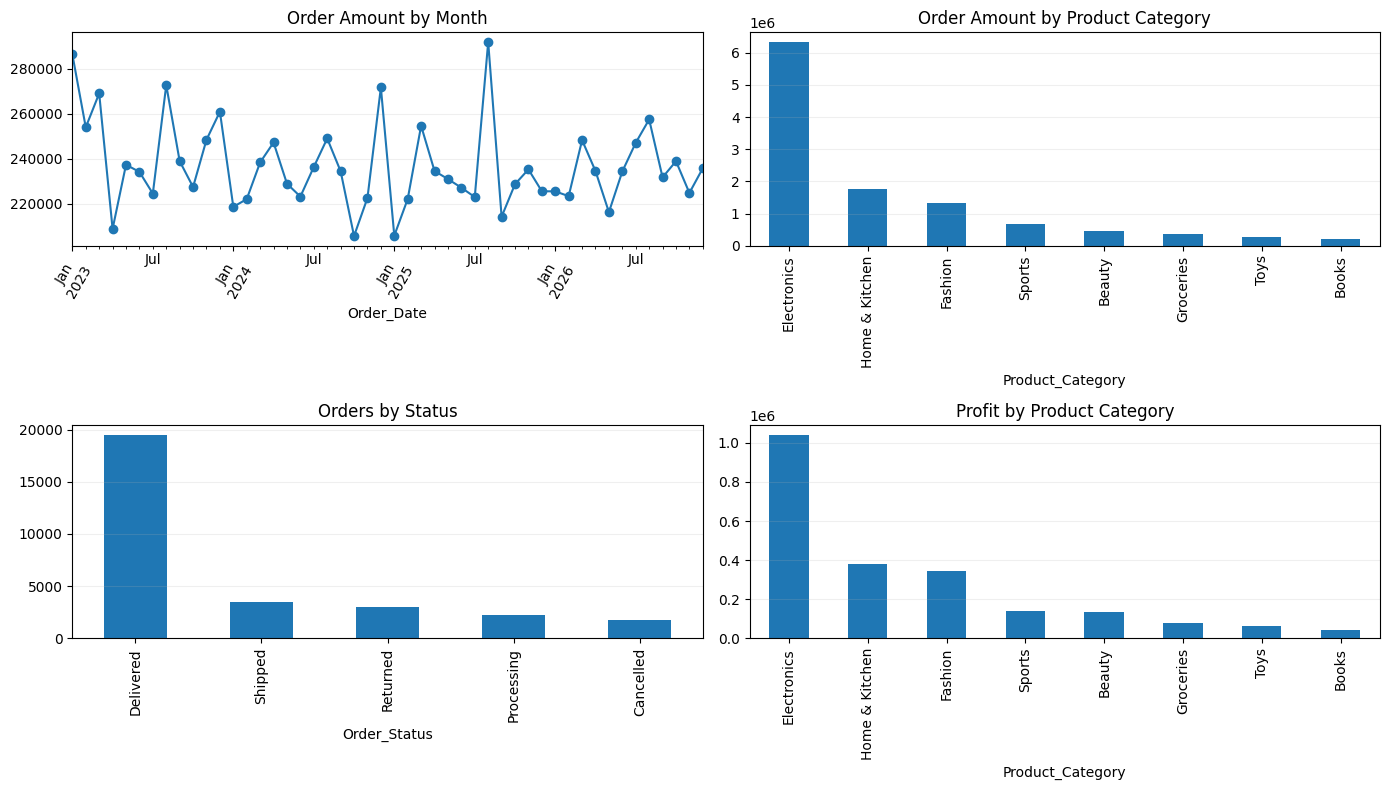

In [12]:
kpis = {
    "Orders": df["Order_ID"].nunique(),
    "Customers": df["Customer_ID"].nunique(),
    "Products": df["Product_ID"].nunique(),
    "Total Order Amount": df["Order_Amount"].sum(),
    "Total Profit": df["Profit_Amount"].sum(),
    "Average Order Amount": df["Order_Amount"].mean(),
    "Average Review Rating": df["Review_Rating"].mean(),
    "Return Rate": (df["Returned"].astype(str).str.lower() == "yes").mean(),
    "Average Delivery Days": df["Delivery_Days"].mean()
}
display(pd.DataFrame({"KPI":kpis.keys(),"Value":kpis.values()}))
monthly = df.groupby(df["Order_Date"].dt.to_period("M"))["Order_Amount"].sum()
category_sales = df.groupby("Product_Category")["Order_Amount"].sum().sort_values(ascending=False)
status_count = df["Order_Status"].value_counts()
category_profit = df.groupby("Product_Category")["Profit_Amount"].sum().sort_values(ascending=False)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
monthly.plot(ax=axes[0,0], marker="o", title="Order Amount by Month")
axes[0,0].tick_params(axis="x", rotation=60)
category_sales.plot(kind="bar", ax=axes[0,1], title="Order Amount by Product Category")
status_count.plot(kind="bar", ax=axes[1,0], title="Orders by Status")
category_profit.plot(kind="bar", ax=axes[1,1], title="Profit by Product Category")
for ax in axes.flat: ax.grid(axis="y", alpha=.2)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "dashboard_preview.png", dpi=150, bbox_inches="tight")
plt.show()


## 6. Kiểm tra mô hình trước khi đưa vào SQL/Tableau
- FactOrders phải có một dòng cho mỗi `Order_ID` (theo cấu trúc dataset hiện tại).
- Mỗi dimension key phải duy nhất.
- Các foreign key trong FactOrders không được null.
- Đối chiếu tổng `Order_Amount`, `Profit_Amount` với KPI từ dữ liệu sạch.
- Lưu ý: không tự tính lại `Order_Amount = Unit_Price * Quantity` khi chưa biết định nghĩa nghiệp vụ về thuế, chiết khấu và phí vận chuyển.